In [1]:
pip install split-folders tensorflow scikit-learn matplotlib seaborn pillow tqdm pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
data_dir = "dataImages/original"

classes = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
print("Classes found:", classes)
print("Number of classes:", len(classes))

Classes found: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of classes: 10


        class  count
3     clothes   1892
4       glass   1736
7     plastic   1597
8       shoes   1449
2   cardboard   1411
6       paper   1336
5       metal    930
0     battery    756
1  biological    699
9       trash    453


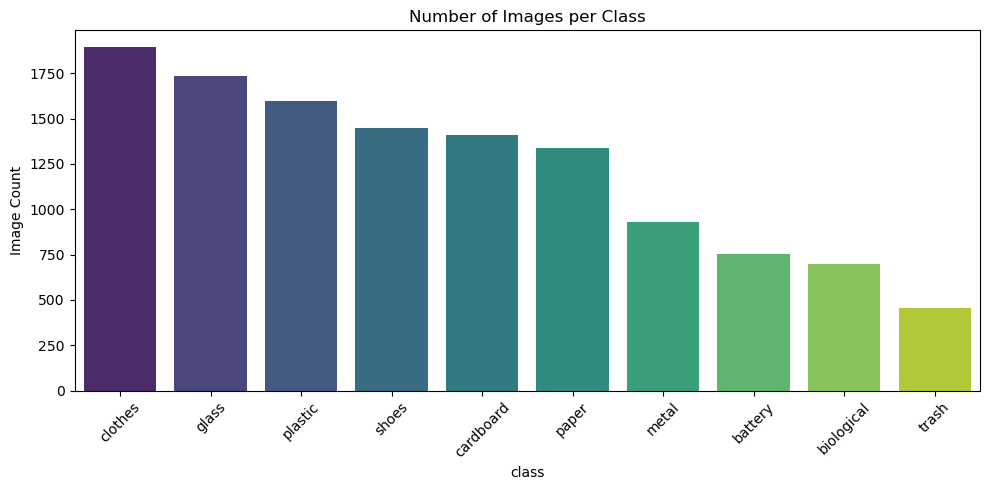

Imbalance ratio (max/min class): 4.18


In [3]:
class_counts = {}
for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    class_counts[cls] = len(os.listdir(cls_path))

df_counts = pd.DataFrame(list(class_counts.items()), columns=["class", "count"]).sort_values("count", ascending=False)
print(df_counts)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_counts, x="class", y="count", hue="class", palette="viridis", legend=False)
plt.title("Number of Images per Class")
plt.xticks(rotation=45)
plt.ylabel("Image Count")
plt.tight_layout()
plt.show()

imbalance_ratio = df_counts["count"].max() / df_counts["count"].min()
print(f"Imbalance ratio (max/min class): {imbalance_ratio:.2f}")

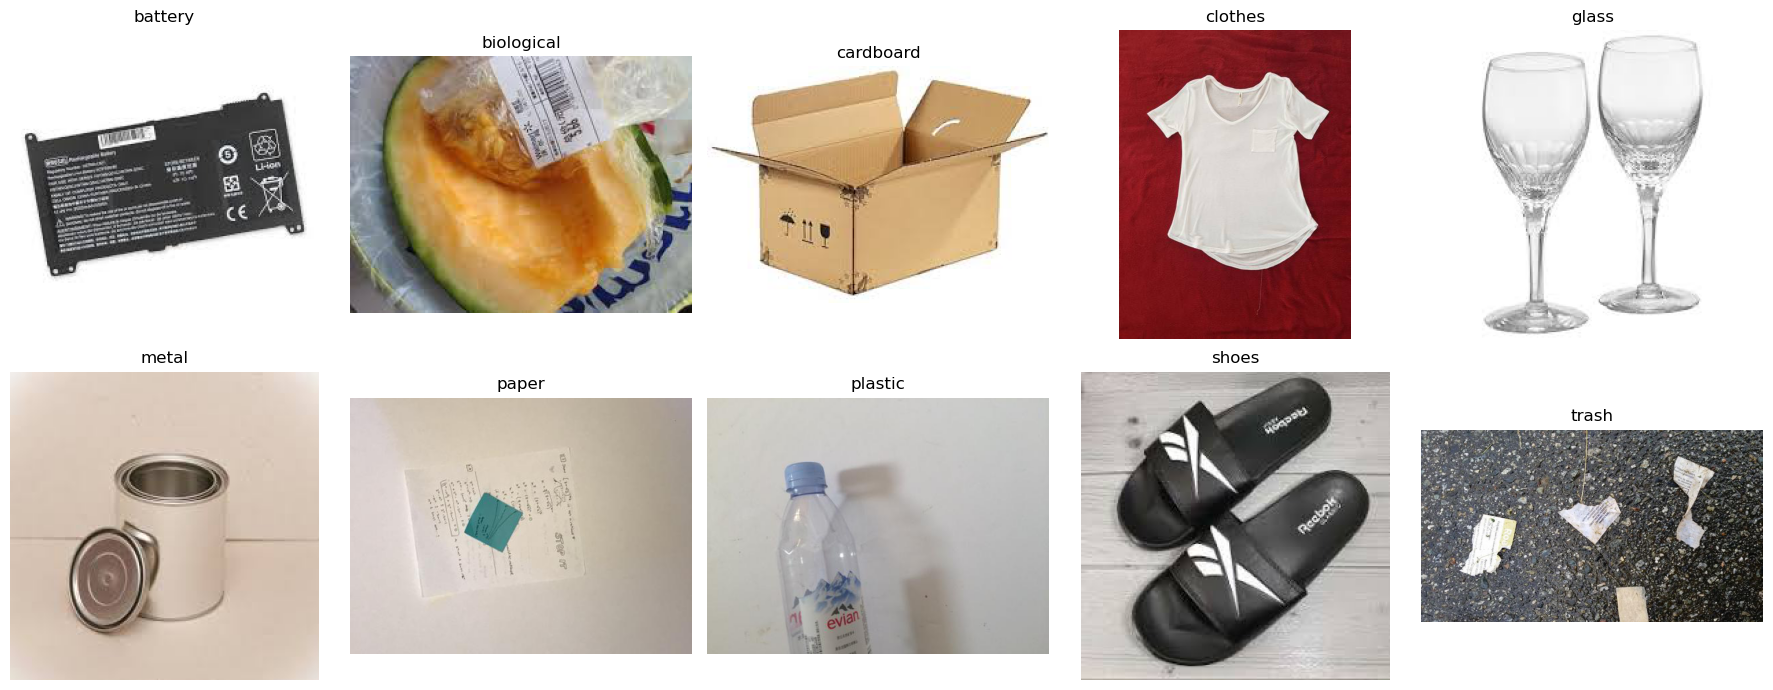

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

for i, cls in enumerate(classes[:10]):
    cls_path = os.path.join(data_dir, cls)
    sample_img = os.listdir(cls_path)[0]
    img = Image.open(os.path.join(cls_path, sample_img))
    axes[i].imshow(img)
    axes[i].set_title(cls)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

trash: 100%|████████████████████████████████████████████████████████████████████████| 453/453 [00:00<00:00, 958.21it/s]


Total images scanned: 12259
Valid images: 12259
Corrupt/unreadable files: 0
Width  - min: 51, max: 7786, mean: 440
Height - min: 71, max: 6283, mean: 431


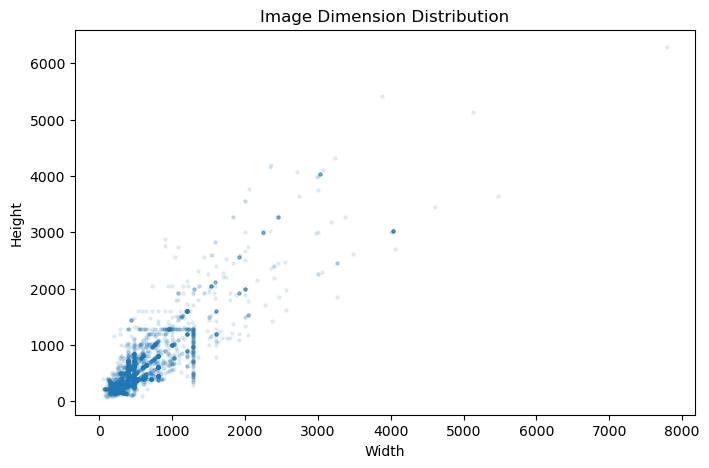

In [5]:
import numpy as np
from tqdm import tqdm

widths, heights, corrupt_files = [], [], []

for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    for fname in tqdm(os.listdir(cls_path), desc=cls):
        fpath = os.path.join(cls_path, fname)
        try:
            with Image.open(fpath) as img:
                img.verify()
            with Image.open(fpath) as img:  # reopen after verify() closes the file pointer
                w, h = img.size
                widths.append(w)
                heights.append(h)
        except Exception:
            corrupt_files.append(fpath)

print(f"Total images scanned: {len(widths) + len(corrupt_files)}")
print(f"Valid images: {len(widths)}")
print(f"Corrupt/unreadable files: {len(corrupt_files)}")
if corrupt_files:
    print("Examples:", corrupt_files[:5])

print(f"Width  - min: {min(widths)}, max: {max(widths)}, mean: {np.mean(widths):.0f}")
print(f"Height - min: {min(heights)}, max: {max(heights)}, mean: {np.mean(heights):.0f}")

plt.figure(figsize=(8, 5))
plt.scatter(widths, heights, alpha=0.1, s=5)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Dimension Distribution")
plt.show()

In [12]:
pip install split-folders

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [6]:
import splitfolders

output_dir = "dataImages/split"

splitfolders.ratio(
    data_dir,          # your original "dataImages/original" folder
    output=output_dir,
    seed=42,
    ratio=(0.7, 0.15, 0.15)  # 70% train, 15% validation, 15% test
)

train_dir = f"{output_dir}/train"
val_dir = f"{output_dir}/val"
test_dir = f"{output_dir}/test"

print("Train:", sum(len(os.listdir(os.path.join(train_dir, c))) for c in classes))
print("Val:  ", sum(len(os.listdir(os.path.join(val_dir, c))) for c in classes))
print("Test: ", sum(len(os.listdir(os.path.join(test_dir, c))) for c in classes))

Copying files: 12259 files [01:14, 163.85 files/s]


Train: 8578
Val:   1833
Test:  1848


In [7]:
IMG_SIZE = (224, 224)   # standard input size expected by ImageNet-pretrained EfficientNet/ResNet
BATCH_SIZE = 32
num_classes = len(classes)

In [8]:
def make_generators(preprocess_fn):
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn,
        rotation_range=20,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.15,
        horizontal_flip=True,
        brightness_range=[0.8, 1.2],
    )
    eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_fn)

    train_gen = train_datagen.flow_from_directory(
        train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=True, seed=42
    )
    val_gen = eval_datagen.flow_from_directory(
        val_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False
    )
    test_gen = eval_datagen.flow_from_directory(
        test_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False
    )
    return train_gen, val_gen, test_gen

In [9]:
from sklearn.utils.class_weight import compute_class_weight

# Use any one generator's labels to compute weights (train set only)
temp_gen = ImageDataGenerator().flow_from_directory(train_dir, target_size=IMG_SIZE, shuffle=False)
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(temp_gen.classes),
    y=temp_gen.classes
)
class_weights = dict(enumerate(class_weights_array))
print("Class weights:", class_weights)

Found 8578 images belonging to 10 classes.
Class weights: {0: 1.6215500945179584, 1: 1.7541922290388547, 2: 0.8690982776089159, 3: 0.6478851963746224, 4: 0.7060082304526749, 5: 1.3176651305683564, 6: 0.917433155080214, 7: 0.7679498657117279, 8: 0.8459566074950691, 9: 2.705993690851735}


In [10]:
def build_model(base_model_fn, input_shape=(224, 224, 3)):
    base_model = base_model_fn(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False  # phase 1: frozen base

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)
    return model, base_model

In [11]:
def train_model(model, base_model, train_gen, val_gen, model_name, epochs_phase1=10, epochs_phase2=10):
    model.compile(optimizer=Adam(learning_rate=1e-3),
                   loss='categorical_crossentropy', metrics=['accuracy'])

    callbacks_p1 = [
        EarlyStopping(patience=4, restore_best_weights=True, monitor='val_accuracy'),
        ModelCheckpoint(f'{model_name}_phase1.keras', save_best_only=True, monitor='val_accuracy')
    ]

    print(f"\n{'='*20} {model_name}: PHASE 1 (frozen base) {'='*20}")
    hist1 = model.fit(train_gen, validation_data=val_gen, epochs=epochs_phase1,
                       callbacks=callbacks_p1, class_weight=class_weights)

    base_model.trainable = True
    fine_tune_at = int(len(base_model.layers) * 0.7)
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    model.compile(optimizer=Adam(learning_rate=1e-5),
                   loss='categorical_crossentropy', metrics=['accuracy'])

    callbacks_p2 = [
        EarlyStopping(patience=5, restore_best_weights=True, monitor='val_accuracy'),
        ModelCheckpoint(f'{model_name}_final.keras', save_best_only=True, monitor='val_accuracy')
    ]

    print(f"\n{'='*20} {model_name}: PHASE 2 (fine-tuning) {'='*20}")
    hist2 = model.fit(train_gen, validation_data=val_gen, epochs=epochs_phase2,
                       callbacks=callbacks_p2, class_weight=class_weights)

    return hist1, hist2

In [12]:
train_gen_eff, val_gen_eff, test_gen_eff = make_generators(effnet_preprocess)
model_eff, base_eff = build_model(EfficientNetB0)
hist1_eff, hist2_eff = train_model(model_eff, base_eff, train_gen_eff, val_gen_eff, "efficientnetb0")

Found 8578 images belonging to 10 classes.
Found 1833 images belonging to 10 classes.
Found 1848 images belonging to 10 classes.

==================== efficientnetb0: PHASE 1 (frozen base) ====================


C:\Users\User\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 484s 2s/step - accuracy: 0.7146 - loss: 0.9182 - val_accuracy: 0.9302 - val_loss: 0.2310
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 333s 1s/step - accuracy: 0.8796 - loss: 0.3444 - val_accuracy: 0.9280 - val_loss: 0.2103
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 329s 1s/step - accuracy: 0.9012 - loss: 0.2944 - val_accuracy: 0.9373 - val_loss: 0.1921
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 328s 1s/step - accuracy: 0.9148 - loss: 0.2538 - val_accuracy: 0.9362 - val_loss: 0.1815
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 324s 1s/step - accuracy: 0.9222 - loss: 0.2241 - val_accuracy: 0.9460 - val_loss: 0.1686
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 325s 1s/step - accuracy: 0.9294 - loss: 0.1982 - val_accuracy: 0.9454 - val_loss: 0.1629
Epoch 7/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 324s 1s/step - accuracy: 0.9222 - loss: 0.2035 - val_accuracy: 0.9444 - val_loss: 0.1664
Epoch 8/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 324s 1s/step - accuracy: 0.9363 - loss: 0.1847 - val_accu

In [13]:
train_gen_res, val_gen_res, test_gen_res = make_generators(resnet_preprocess)
model_res, base_res = build_model(ResNet50)
hist1_res, hist2_res = train_model(model_res, base_res, train_gen_res, val_gen_res, "resnet50")

Found 8578 images belonging to 10 classes.
Found 1833 images belonging to 10 classes.
Found 1848 images belonging to 10 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step

==================== resnet50: PHASE 1 (frozen base) ====================
Epoch 1/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 770s 3s/step - accuracy: 0.6498 - loss: 1.1193 - val_accuracy: 0.8969 - val_loss: 0.3029
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 745s 3s/step - accuracy: 0.8614 - loss: 0.4157 - val_accuracy: 0.9154 - val_loss: 0.2495
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 740s 3s/step - accuracy: 0.8785 - loss: 0.3415 - val_accuracy: 0.9269 - val_loss: 0.2148
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 741s 3s/step - accuracy: 0.8972 - loss: 0.3014 - val_accuracy: 0.9182 - val_loss: 0.2299
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 743s 3s/step - accuracy: 0.8939 - loss: 0.3053 - val_accuracy: 0.9280 - val_loss: 0.2235
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 744s 3s/step - accuracy: 0.9137 - loss: 0.2573 - val_accurac

In [14]:
model_eff.save("efficientnetb0_garbage_classifier.keras")
model_res.save("resnet50_garbage_classifier.keras")

print("Both models saved successfully.")

Both models saved successfully.


In [15]:
import os

for f in ["efficientnetb0_garbage_classifier.keras", "resnet50_garbage_classifier.keras"]:
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"{f}: {size_mb:.2f} MB")
    

efficientnetb0_garbage_classifier.keras: 41.68 MB
resnet50_garbage_classifier.keras: 225.00 MB


In [16]:
from tensorflow.keras.models import load_model

test_load = load_model("efficientnetb0_garbage_classifier.keras")
print("Reloaded successfully:", test_load.summary())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling (Rescaling)         │ (None, 224, 224, 3)       │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ normalization (Normalization) │ (None, 224, 224, 3)       │               7 │ rescaling[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_1 (Rescaling)       │ (None, 224, 224, 3)       │               0 │ normalization[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv_pad (ZeroPadding2D) │ (None, 225, 225, 3)       │               0 │ rescaling_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv (Conv2D)            │ (None, 112, 112, 32)      │             864 │ stem_conv_pad[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_bn (BatchNormalization)  │ (None, 112, 112, 32)      │             128 │ stem_conv[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_activation (Activation)  │ (None, 112, 112, 32)      │               0 │ stem_bn[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_dwconv                │ (None, 112, 112, 32)      │             288 │ stem_activation[0][0]      │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_bn                    │ (None, 112, 112, 32)      │             128 │ block1a_dwconv[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_activation            │ (None, 112, 112, 32)      │               0 │ block1a_bn[0][0]           │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_squeeze            │ (None, 32)                │               0 │ block1a_activation[0][0]   │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reshape (Reshape)  │ (None, 1, 1, 32)          │               0 │ block1a_se_squeeze[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reduce (Conv2D)    │ (None, 1, 1, 8)           │             264 │ block1a_se_reshape[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_expand (Conv2D)    │ (None, 1, 1, 32)          │             288 │ block1a_se_reduce[0][0]    │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 10,703,611 (40.83 MB)

 Trainable params: 3,244,390 (12.38 MB)

 Non-trainable params: 970,439 (3.70 MB)

 Optimizer params: 6,488,782 (24.75 MB)

Reloaded successfully: None


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from sklearn.metrics import classification_report, confusion_matrix

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
test_dir = "dataImages/split/test"  # adjust to your actual path

# Load the saved models
model_eff = load_model("efficientnetb0_final.keras")
model_res = load_model("resnet50_final.keras")

# Recreate test generators (no training involved — just reading test images)
eff_test_datagen = ImageDataGenerator(preprocessing_function=effnet_preprocess)
res_test_datagen = ImageDataGenerator(preprocessing_function=resnet_preprocess)

test_gen_eff = eff_test_datagen.flow_from_directory(
    test_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)
test_gen_res = res_test_datagen.flow_from_directory(
    test_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

class_labels = list(test_gen_eff.class_indices.keys())

Found 1848 images belonging to 10 classes.
Found 1848 images belonging to 10 classes.


C:\Users\User\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


58/58 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step

==================== EfficientNetB0: TEST SET RESULTS ====================
              precision    recall  f1-score   support

     battery       0.96      0.96      0.96       114
  biological       0.98      1.00      0.99       106
   cardboard       0.93      0.93      0.93       213
     clothes       0.99      0.99      0.99       285
       glass       0.93      0.90      0.91       261
       metal       0.79      0.95      0.86       140
       paper       0.93      0.87      0.90       201
     plastic       0.91      0.89      0.90       241
       shoes       0.98      0.99      0.98       218
       trash       0.82      0.84      0.83        69

    accuracy                           0.93      1848
   macro avg       0.92      0.93      0.93      1848
weighted avg       0.94      0.93      0.93      1848



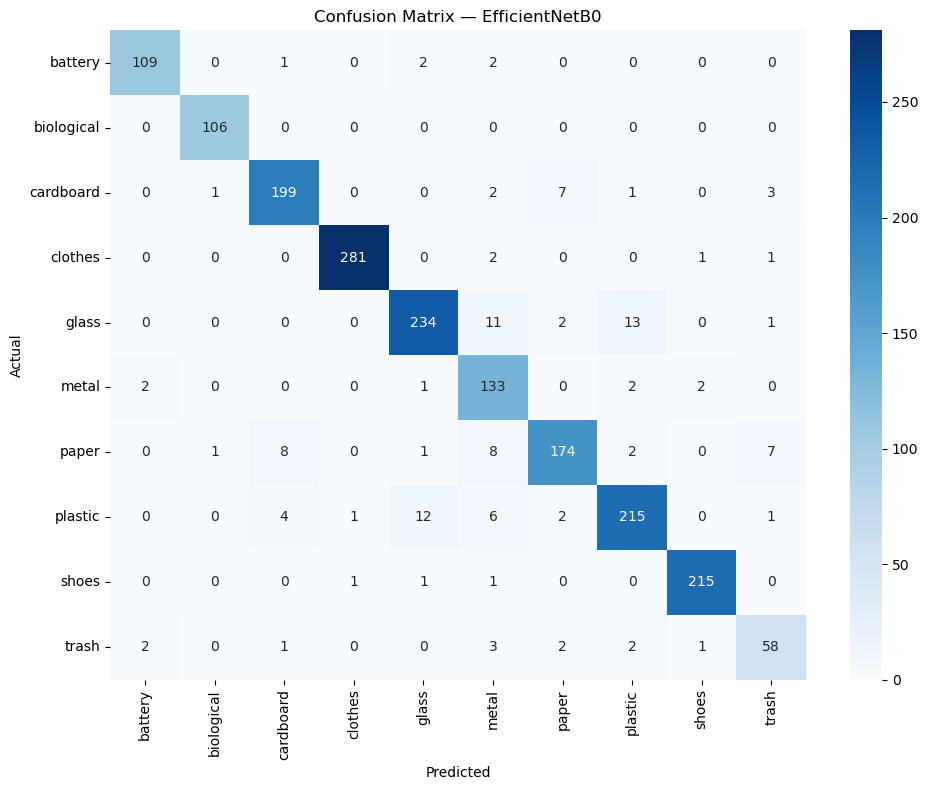

C:\Users\User\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


58/58 ━━━━━━━━━━━━━━━━━━━━ 177s 3s/step

==================== ResNet50: TEST SET RESULTS ====================
              precision    recall  f1-score   support

     battery       0.96      0.96      0.96       114
  biological       0.98      1.00      0.99       106
   cardboard       0.96      0.94      0.95       213
     clothes       0.99      0.99      0.99       285
       glass       0.93      0.94      0.94       261
       metal       0.86      0.94      0.90       140
       paper       0.92      0.89      0.90       201
     plastic       0.95      0.93      0.94       241
       shoes       1.00      0.98      0.99       218
       trash       0.87      0.87      0.87        69

    accuracy                           0.95      1848
   macro avg       0.94      0.94      0.94      1848
weighted avg       0.95      0.95      0.95      1848



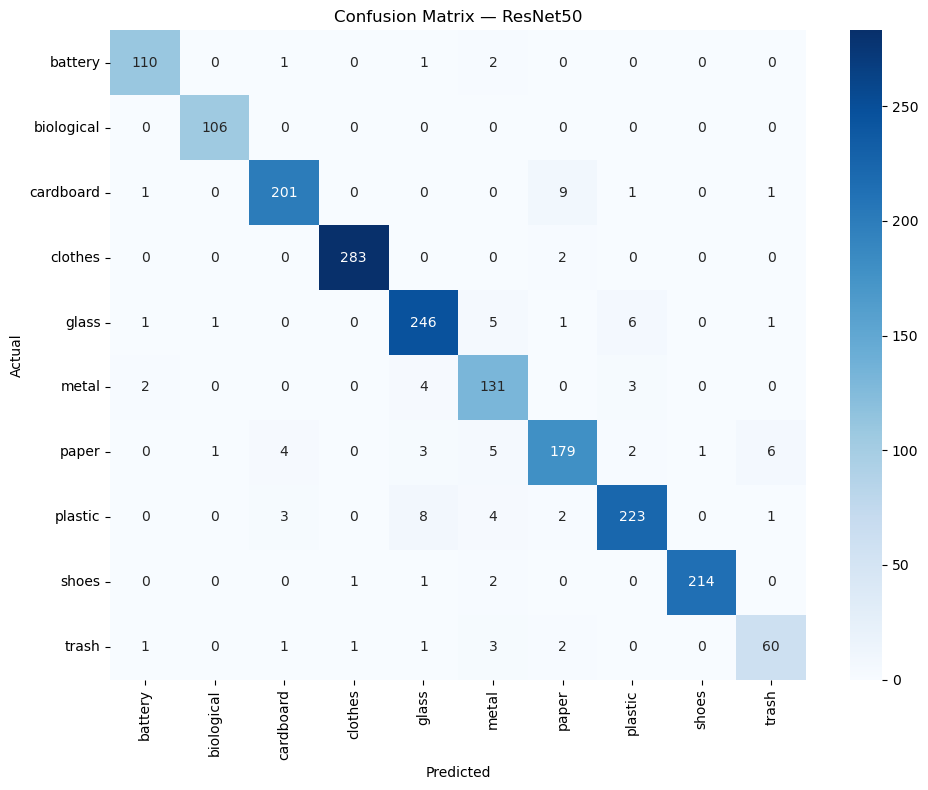


EfficientNetB0 — Test Acc: 0.9329, Macro F1: 0.9265
ResNet50       — Test Acc: 0.9486, Macro F1: 0.9428


In [3]:
def evaluate_model(model, test_gen, model_name, class_labels):
    test_gen.reset()
    preds = model.predict(test_gen)
    y_pred = np.argmax(preds, axis=1)
    y_true = test_gen.classes

    print(f"\n{'='*20} {model_name}: TEST SET RESULTS {'='*20}")
    report = classification_report(y_true, y_pred, target_names=class_labels, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=class_labels))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.savefig(f"confusion_matrix_{model_name}.png", dpi=150)
    plt.show()

    return report["accuracy"], report["macro avg"]["f1-score"]

acc_eff, f1_eff = evaluate_model(model_eff, test_gen_eff, "EfficientNetB0", class_labels)
acc_res, f1_res = evaluate_model(model_res, test_gen_res, "ResNet50", class_labels)

print(f"\nEfficientNetB0 — Test Acc: {acc_eff:.4f}, Macro F1: {f1_eff:.4f}")
print(f"ResNet50       — Test Acc: {acc_res:.4f}, Macro F1: {f1_res:.4f}")